## PROYECTO FINAL: Clasificación de géneros de canciones

#PREPARACIÓN DEL CONJUNTO DE DATOS




In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import KFold, cross_val_score

from sklearn.decomposition import PCA
from sklearn.metrics import precision_score, recall_score, f1_score

from sklearn.preprocessing import StandardScaler

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
tracks = pd.read_csv('/content/drive/MyDrive/DATA_PRACTICA/songs.csv', sep = ",")
tracks.head()

,track_id,bit_rate,comments,composer,date_created,date_recorded,duration,favorites,genre_top,genres,...,information,interest,language_code,license,listens,lyricist,number,publisher,tags,title
0,135,256000,1,NaN,2008-11-26 01:43:26,2008-11-26 00:00:00,837,0,Rock,"[45, 58]",...,NaN,2484,en,Attribution-NonCommercial-ShareAlike 3.0 Inter...,1832,NaN,0,NaN,[],Father's Day
1,136,256000,1,NaN,2008-11-26 01:43:35,2008-11-26 00:00:00,509,0,Rock,"[45, 58]",...,NaN,1948,en,Attribution-NonCommercial-ShareAlike 3.0 Inter...,1498,NaN,0,NaN,[],Peel Back The Mountain Sky
2,151,192000,0,NaN,2008-11-26 01:44:55,NaN,192,0,Rock,[25],...,NaN,701,en,Attribution-NonCommercial-ShareAlike 3.0 Inter...,148,NaN,4,NaN,[],Untitled 04
3,152,192000,0,NaN,2008-11-26 01:44:58,NaN,193,0,Rock,[25],...,NaN,637,en,Attribution-NonCommercial-ShareAlike 3.0 Inter...,98,NaN,11,NaN,[],Untitled 11
4,153,256000,0,Arc and Sender,2008-11-26 01:45:00,2008-11-26 00:00:00,405,5,Rock,[26],...,NaN,354,en,Attribution-NonCommercial-NoDerivatives (aka M...,424,NaN,2,NaN,[],Hundred-Year Flood


In [ ]:
echonest_metrics = pd.read_json('/content/drive/MyDrive/DATA_PRACTICA/echonest-metrics.json', precise_float=True)
echonest_metrics.head()

,track_id,acousticness,danceability,energy,instrumentalness,liveness,speechiness,tempo,valence
0,2,0.416675,0.675894,0.634476,0.010628,0.177647,0.159310,165.922,0.576661
1,3,0.374408,0.528643,0.817461,0.001851,0.105880,0.461818,126.957,0.269240
2,5,0.043567,0.745566,0.701470,0.000697,0.373143,0.124595,100.260,0.621661
3,10,0.951670,0.658179,0.924525,0.965427,0.115474,0.032985,111.562,0.963590
4,134,0.452217,0.513238,0.560410,0.019443,0.096567,0.525519,114.290,0.894072


In [ ]:
echo_tracks = pd.merge(echonest_metrics, tracks[['track_id', 'genre_top']],on='track_id')

In [ ]:
echo_tracks.head()

,track_id,acousticness,danceability,energy,instrumentalness,liveness,speechiness,tempo,valence,genre_top
0,2,0.416675,0.675894,0.634476,0.010628,0.177647,0.159310,165.922,0.576661,Hip-Hop
1,3,0.374408,0.528643,0.817461,0.001851,0.105880,0.461818,126.957,0.269240,Hip-Hop
2,5,0.043567,0.745566,0.701470,0.000697,0.373143,0.124595,100.260,0.621661,Hip-Hop
3,134,0.452217,0.513238,0.560410,0.019443,0.096567,0.525519,114.290,0.894072,Hip-Hop
4,153,0.988306,0.255661,0.979774,0.973006,0.121342,0.051740,90.241,0.034018,Rock


# PASO 2: LIMPIEZA DE DATOS

In [ ]:
print(echo_tracks.info())

<class 'pandas.core.frame.DataFrame'>
Int64Index: 4802 entries, 0 to 4801
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_id          4802 non-null   int64  
 1   acousticness      4802 non-null   float64
 2   danceability      4802 non-null   float64
 3   energy            4802 non-null   float64
 4   instrumentalness  4802 non-null   float64
 5   liveness          4802 non-null   float64
 6   speechiness       4802 non-null   float64
 7   tempo             4802 non-null   float64
 8   valence           4802 non-null   float64
 9   genre_top         4802 non-null   object 
dtypes: float64(8), int64(1), object(1)
memory usage: 412.7+ KB
None


In [ ]:
echonest_metrics.shape

(13129, 9)

In [ ]:
echonest_metrics.count()

track_id            13129
acousticness        13129
danceability        13129
energy              13129
instrumentalness    13129
liveness            13129
speechiness         13129
tempo               13129
valence             13129
dtype: int64

# PASO 3: ANÁLISIS DE DATOS

# **Relaciones por pares entre variables continuas**
Normalmente queremos evitar el uso de variables que tengan fuertes correlaciones entre sí (evitando así la redundancia de características)

* Para mantener el modelo simple y mejorar la interpretabilidad (con muchas
características, corremos el riesgo de sobreajustar).

* Cuando nuestros conjuntos de datos son muy grandes, usar menos funciones puede acelerar drásticamente nuestro tiempo de cálculo.

* Para tener una idea de si hay características fuertemente correlacionadas en nuestros datos.


In [ ]:
# Create a correlation matrix
corr_metrics = echo_tracks.corr()
corr_metrics.style.background_gradient()

<ipython-input-70-48e94c368ccc>:2: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  corr_metrics = echo_tracks.corr()


,track_id,acousticness,danceability,energy,instrumentalness,liveness,speechiness,tempo,valence
track_id,1.000000,-0.372282,0.049454,0.140703,-0.275623,0.048231,-0.026995,-0.025392,0.010070
acousticness,-0.372282,1.000000,-0.028954,-0.281619,0.194780,-0.019991,0.072204,-0.026310,-0.013841
danceability,0.049454,-0.028954,1.000000,-0.242032,-0.255217,-0.106584,0.276206,-0.242089,0.473165
energy,0.140703,-0.281619,-0.242032,1.000000,0.028238,0.113331,-0.109983,0.195227,0.038603
instrumentalness,-0.275623,0.194780,-0.255217,0.028238,1.000000,-0.091022,-0.366762,0.022215,-0.219967
liveness,0.048231,-0.019991,-0.106584,0.113331,-0.091022,1.000000,0.041173,0.002732,-0.045093
speechiness,-0.026995,0.072204,0.276206,-0.109983,-0.366762,0.041173,1.000000,0.008241,0.149894
tempo,-0.025392,-0.026310,-0.242089,0.195227,0.022215,0.002732,0.008241,1.000000,0.052221
valence,0.010070,-0.013841,0.473165,0.038603,-0.219967,-0.045093,0.149894,0.052221,1.000000


In [ ]:
# Define our features
features = echo_tracks.drop(['genre_top', 'track_id'], axis=1)

# Define our labels
labels = echo_tracks['genre_top']



# Scale the features and set the values to a new variable
scaler = StandardScaler()
scaled_train_features = scaler.fit_transform(features)

[0.24297674 0.18044316 0.13650309 0.12994089 0.11056248 0.08302245
 0.06923783 0.04731336]
8


Text(0.5, 0, 'Principal Component #')

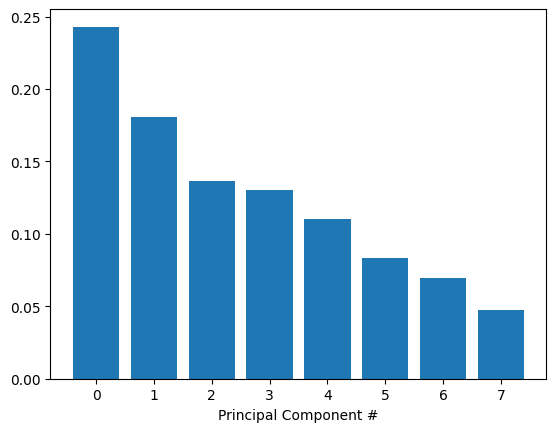

In [ ]:
# This is just to make plots appear in the notebook
%matplotlib inline

# Import our plotting module, and PCA class
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Get our explained variance ratios from PCA using all features
pca = PCA()
pca.fit(scaled_train_features)
exp_variance = pca.explained_variance_ratio_

print(pca.explained_variance_ratio_)
print(pca.n_components_)

# plot the explained variance using a barplot
fig, ax = plt.subplots()
ax.bar(range(pca.n_components_), exp_variance, color='white') # Las barras son de color blanco
ax.set_facecolor('darkblue') # El fondo es de color azul oscuro
ax.set_xlabel('Componente Principal') # Etiqueta del eje X
ax.set_ylabel('Varianza Explicada (%)') # Etiqueta del eje Y
ax.set_title('Varianza Explicada Por Cada Componente Principal') # Título del gráfico
plt.show()

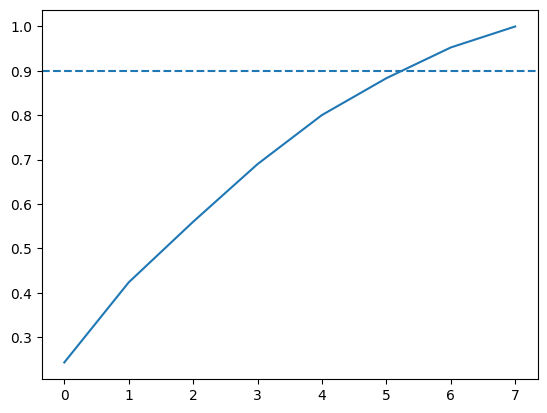

In [ ]:

# Calculate the cumulative explained variance
cum_exp_variance = np.cumsum(exp_variance)

# Plot the cumulative explained variance and draw a dashed line at 0.90.
fig, ax = plt.subplots()
ax.plot(range(pca.n_components_), cum_exp_variance)
ax.axhline(y=0.9, linestyle='--')
n_components = 6

# Perform PCA with the chosen number of components and project data onto components
pca = PCA(n_components, random_state=10)
pca.fit(scaled_train_features)
pca_projection = pca.transform(scaled_train_features)

# PASO 4: CONSTRUCCION DEL MODELO DE PREDICCIÓN

* **Utilizamos la proyección PCA de menor dimensión de los datos para clasificar las canciones por géneros.**

* **Primero tenemos que dividir nuestro conjunto de datos en subconjuntos de "entrenamiento" y "prueba", donde el subconjunto de "entrenamiento" se utilizará para entrenar nuestro modelo, mientras que el conjunto de datos de "prueba" permite validar el rendimiento del modelo.**

In [ ]:

# Dividimos nuestros datos para entrenamiento y prueba
train_features, test_features, train_labels, test_labels = train_test_split(pca_projection,
labels,random_state=10)

# Entrenamos nuestro árbol de decisión
tree = DecisionTreeClassifier(random_state=10)
tree.fit(train_features, train_labels)

#Calculamos las predicciones en un conjunto de data de prueba
pred_labels_tree = tree.predict(test_features)
tree.score(test_features, test_labels)

0.7362637362637363

# PASO 5: EVALUACIÓN DEL MODELO



*   Aunque el rendimiento de nuestro árbol es decente, no podeos afirmar t odavía que esta funcionando eficienteme, por lo que evularemos nuestro modelo mediante métricas de rendimiento, una métrica que usaremos para esto será una matriz de confusión y otras métricas de rendimiento adicionales



In [ ]:
# Create the classification report for both models

class_rep_tree = classification_report(test_labels, pred_labels_tree)
print("Decision Tree: \n", class_rep_tree)

Decision Tree: 
               precision    recall  f1-score   support

     Hip-Hop       0.60      0.60      0.60       235
        Rock       0.90      0.90      0.90       966

    accuracy                           0.84      1201
   macro avg       0.75      0.75      0.75      1201
weighted avg       0.84      0.84      0.84      1201



Precision: 0.736
Recall: 0.736
F1-Score: 0.736


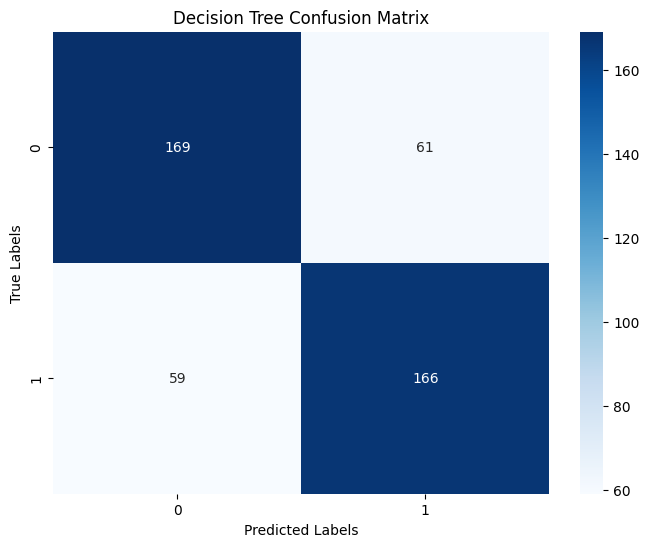

In [ ]:
# Creamos la matriz de confusión para evaluar los valores de predicción
def print_metrics(model_name, true_labels, pred_labels):
    class_rep = classification_report(true_labels, pred_labels)
    precision = precision_score(true_labels, pred_labels, average='weighted')
    recall = recall_score(true_labels, pred_labels, average='weighted')
    f1 = f1_score(true_labels, pred_labels, average='weighted')

    #print(f"{model_name}:")
    #print(f"Classification Report:\n{class_rep}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall: {recall:.3f}")
    print(f"F1-Score: {f1:.3f}")

    # Plot confusion matrix
    cm = confusion_matrix(true_labels, pred_labels)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, cmap="Blues", fmt="d")
    plt.title(f"{model_name} Confusion Matrix")
    plt.xlabel("Predicted Labels")
    plt.ylabel("True Labels")
    plt.show()

print_metrics("Decision Tree", test_labels, pred_labels_tree)

 El modelo de árbol de decision ha tenido un rendimiento notable al predecir  169 instancias correctamente clasificadas. Sin embargo, se observa que ha tenido dificultades al predecir al predecir el otro valor, como se refleja en los valores de la matriz de confusión.

Esto sugiere que el modelo puede estar sesgado o tener limitaciones en la capacidad de generalización.

# PASO 6 AJUSTES DEL MODELO

* Observamos nuestro informe de clasificación, podemos ver que las canciones de rock están bastante bien clasificadas, pero las de hip-hop están desproporcionadamente mal clasificadas como canciones de rock.

*  Si nos fijamos en el número de puntos de datos que tenemos para cada clase, vemos que tenemos muchos más puntos de datos para la clasificación de rock que para la de hip-hop, lo que podría sesgar la capacidad de nuestro modelo para distinguir entre clases.

* Esto nos indica que la mayor parte de la precisión de nuestro modelo se debe a su capacidad para clasificar sólo canciones de rock (no es lo ideal).Para tenerlo en cuenta, podemos ponderar el valor de una clasificación correcta en cada clase de forma inversa al número de puntos de datos de cada clase.

*  Dado que una clasificación correcta de "Rock" no es más importante que una clasificación correcta de "Hip-Hop" (y viceversa), al ponderar nuestras clases sólo tenemos que tener en cuenta las diferencias en el tamaño de la muestra de nuestros puntos de datos, y no la importancia relativa de cada clase.

In [ ]:
# Creamos Subconjunto de datos  de una proporción equilibrada
hop_only = echo_tracks.loc[echo_tracks['genre_top'] == 'Hip-Hop']
rock_only = echo_tracks.loc[echo_tracks['genre_top'] == 'Rock']

# Subconjunto solo de las canciones de rock y  muestra del mismo tamaño que las canciones de hip-hop
rock_only = rock_only.sample(hop_only.shape[0], random_state=10)

# Concatenamos los marcos de datos hop_only y rock_only
rock_hop_bal = pd.concat([rock_only, hop_only])

# Las características, etiquetas y proyección PCA se crean para el marco de datos equilibrado.
features = rock_hop_bal.drop(['genre_top', 'track_id'], axis=1)
labels = rock_hop_bal['genre_top']
pca_projection = pca.fit_transform(scaler.fit_transform(features))

# Redefinimos el conjunto de entrenamiento y prueba con la proyección_pca a partir de los datos equilibrados
train_features, test_features, train_labels, test_labels = train_test_split(
    pca_projection, labels, random_state=10)

Hemos equilibrado nuestro conjunto de datos, pero al hacerlo hemos eliminado muchos puntos de datos que podrían haber sido cruciales para entrenar nuestros modelos. Comprobaremos si el equilibrio de los datos mejora el sesgo del modelo

In [ ]:
#Entrenamos nuestro árbol de decisión en los datos equilibrados
tree = DecisionTreeClassifier(random_state=10)
tree.fit(train_features, train_labels)
pred_labels_tree = tree.predict(test_features)

# Evalumaos
print("Decision Tree: \n", classification_report(test_labels, pred_labels_tree))


Decision Tree: 
               precision    recall  f1-score   support

     Hip-Hop       0.74      0.73      0.74       230
        Rock       0.73      0.74      0.73       225

    accuracy                           0.74       455
   macro avg       0.74      0.74      0.74       455
weighted avg       0.74      0.74      0.74       455



* Utilizacimos validación cruzada para evaluar nuestro modelo

* Hemos tenido éxito. El equilibrio de los datos ha eliminado el sesgo hacia la clase más prevalente.  

* Utilizamos la validación cruzada para evaluar el rendimiento de un modelo de aprendizaje automático  en nuevos datos. Esto nos ayuda a garantizar que el modelo no esté sobreajustado y que pueda generalizarse a datos no vistos.

In [ ]:
from sklearn.model_selection import KFold, cross_val_score
# Set up our K-fold cross-validation
kf = KFold(10)
tree = DecisionTreeClassifier(random_state=10)

# Train our models using KFold cv
tree_score = cross_val_score(tree, pca_projection, labels, cv=kf)

# Print the mean of each array o scores
print("Decision Tree:", np.mean(tree_score))

Decision Tree: 0.7489010989010989


# RESULTADOS